# Predicting the Next Word with a Tiny Keras MLP

Copyright (c) jphall@gwu.edu, 2026-2027.

Licensed under the MIT License. This notebook accompanies `lecture_1.tex`: it tokenizes **see spot run fast**, trains a small supervised feed-forward network, decodes its next-token prediction, and plots training progress and learned token embeddings.

## 1. Imports and compute device

TensorFlow/Keras uses a GPU automatically when one is available and otherwise runs on CPU without intervention.

In [1]:
# 1. Imports and compute device
import random

import keras
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from keras import layers

# Fixed seeds make this small classroom demonstration reproducible.
random.seed(7)
np.random.seed(7)
keras.utils.set_random_seed(7)
gpu_names = [gpu.name for gpu in tf.config.list_physical_devices("GPU")]
print(f"Keras backend: {keras.config.backend()}; device: {gpu_names or ['CPU']}")

I0000 00:00:1792335235.802111  491425 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Keras backend: tensorflow; device: ['/physical_device:GPU:0', '/physical_device:GPU:1']


## 2. Tokenize a sentence into context--target examples

The **context-window length is $L=4$ tokens**: each prediction can use at most four preceding token IDs. `<pad>` is ID 0; shorter prefixes are left-padded to this common length.

In [2]:
# 2. Tokenize a sentence into context--target examples
vocabulary = ["<pad>", "see", "spot", "run", "fast", "<eot>"]
token_to_id = {token: i for i, token in enumerate(vocabulary)}
id_to_token = dict(enumerate(vocabulary))
sentence = ["see", "spot", "run", "fast", "<eot>"]
context_width = 4  # Context-window length L: four token positions per prediction.

contexts, targets = [], []
for stop in range(1, len(sentence)):
    # Left padding preserves the most recent tokens in a fixed-width MLP input.
    prefix_ids = [token_to_id[token] for token in sentence[:stop]]
    contexts.append(([token_to_id["<pad>"]] * (context_width - len(prefix_ids))) + prefix_ids)
    targets.append(token_to_id[sentence[stop]])
X = np.array(contexts, dtype=np.int32)
y = np.array(targets, dtype=np.int32)
print(list(zip(contexts, [id_to_token[target] for target in targets])))

[([0, 0, 0, 1], 'spot'), ([0, 0, 1, 2], 'run'), ([0, 1, 2, 3], 'fast'), ([1, 2, 3, 4], '<eot>')]


## 3. Build the Keras MLP

The network matches slide 3: four token IDs select two-dimensional embeddings, which flatten to eight inputs for four `tanh` hidden units and six next-token scores.

In [3]:
# 3. Build the Keras MLP
# Layer flow: 4 token IDs -> 4 × 2 embeddings -> 8 flattened coordinates -> 4 tanh units -> 6 probabilities
# [x1, x2, x3, x4] -> [e11, e12, ..., e42] -> [h1, h2, h3, h4] -> [p0, ..., p5]
# The learned table has one 2-D row for each of 6 vocabulary IDs: E has shape (6, 2).
# Looking up this four-token context selects four rows, so E_x has shape (4, 2).
# Composition rule: one layer's output shape must match the next layer's input shape.
# Here (4, 2) embeddings flatten to 8, then Dense layers connect 8 -> 4 -> 6.
embedding_dim, hidden_units = 2, 4
inputs = keras.Input(shape=(context_width,), dtype="int32", name="token_ids")  # Four-token context window.
embedded = layers.Embedding(len(vocabulary), embedding_dim, name="embedding")(inputs)
flattened = layers.Flatten(name="flatten_embeddings")(embedded)  # Converts 4 × 2 coordinates into 8 inputs.
hidden = layers.Dense(hidden_units, activation="tanh", name="hidden_tanh")(flattened)
outputs = layers.Dense(len(vocabulary), activation="softmax", name="next_token_probabilities")(hidden)
model = keras.Model(inputs, outputs, name="next_token_mlp")
# sparse_categorical_crossentropy is categorical cross-entropy (multiclass log loss) for an integer token target.
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.05), loss="sparse_categorical_crossentropy", metrics=["accuracy"]) 

I0000 00:00:1792335237.651485  491425 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 665 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2080 Ti, pci bus id: 0000:1a:00.0, compute capability: 7.5
I0000 00:00:1792335237.653205  491425 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 7459 MB memory:  -> device: 1, name: NVIDIA GeForce RTX 2080 Ti, pci bus id: 0000:68:00.0, compute capability: 7.5


Model: "next_token_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ token_ids (InputLayer)          │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 4, 2)           │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_embeddings (Flatten)    │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_tanh (Dense)             │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ next_token_probabilities        │ (None, 6)              │            30 │
│ (Dense)                         │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 78 (312.00 B)

 Trainable params: 78 (312.00 B)

 Non-trainable params: 0 (0.00 B)

...

1/1 - 0s - 46ms/step - accuracy: 1.0000 - loss: 0.0014


Epoch 199/200


1/1 - 0s - 43ms/step - accuracy: 1.0000 - loss: 0.0014


Epoch 200/200


1/1 - 0s - 44ms/step - accuracy: 1.0000 - loss: 0.0014


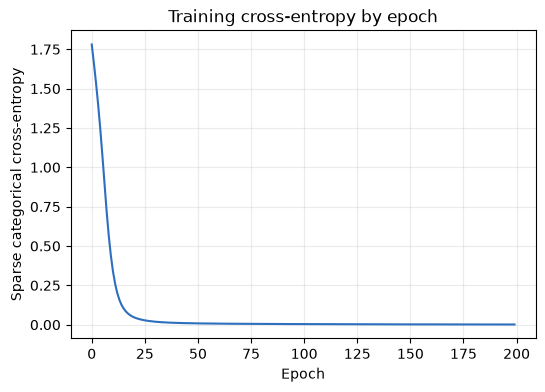

In [4]:
# 4. Summarize and train the Keras MLP
# Parameter counts: embedding = 6 vocabulary rows × 2 coordinates = 12.
# hidden_tanh = 8 flattened inputs × 4 units + 4 biases = 36.
# next_token_probabilities = 4 hidden units × 6 outputs + 6 biases = 30.
# Total trainable parameters = 12 + 36 + 30 = 78.
model.summary()  # Keras prints layer shapes and parameter counts for comparison with slides 3--4.
history = model.fit(X, y, epochs=200, verbose=2)  # Verbose output reports every training epoch.

plt.figure(figsize=(6, 4))
plt.plot(history.history["loss"], color="#2d6ebf")
plt.title("Training cross-entropy by epoch")
plt.xlabel("Epoch")
plt.ylabel("Sparse categorical cross-entropy")
plt.grid(alpha=0.25)
plt.show()

## 5. Predict, detokenize, and plot the learned vocabulary

The maximum-probability ID is converted back to a token. The final panel plots the two coordinates in the learned embedding table.

see spot run -> fast
{'<pad>': np.float32(0.0), 'see': np.float32(0.0), 'spot': np.float32(0.0), 'run': np.float32(0.001), 'fast': np.float32(0.999), '<eot>': np.float32(0.0)}


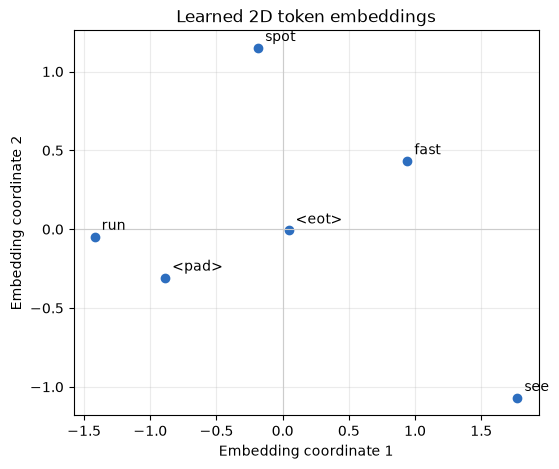

In [5]:
# 5. Predict, detokenize, and plot the learned vocabulary
context = np.array([[0, 1, 2, 3]], dtype=np.int32)
probabilities = model.predict(context, verbose=0)[0]
prediction_id = int(probabilities.argmax())
print(f"see spot run -> {id_to_token[prediction_id]}")
print(dict(zip(vocabulary, probabilities.round(3))))

embedding_points = model.get_layer("embedding").get_weights()[0]
plt.figure(figsize=(6, 5))
for token, point in zip(vocabulary, embedding_points):
    plt.scatter(point[0], point[1], color="#2d6ebf")
    plt.annotate(token, point, xytext=(5, 5), textcoords="offset points")
plt.axhline(0, color="0.8", linewidth=0.8)
plt.axvline(0, color="0.8", linewidth=0.8)
plt.title("Learned 2D token embeddings")
plt.xlabel("Embedding coordinate 1")
plt.ylabel("Embedding coordinate 2")
plt.grid(alpha=0.25)
plt.show()